> **🧭 Navigasi Proyek CRISP-DM:**
> [🏠 00. Business Understanding](./00_Index_dan_Business_Understanding.ipynb) | [📊 01. Data Understanding & EDA](./01_Data_Understanding_dan_EDA.ipynb) | [⚙️ 02. Data Preparation & 32 Fitur](./02_Data_Preparation_Chunking_dan_Ekstraksi_32Fitur.ipynb) | [🧠 03. Modeling & Benchmarking](./03_Modeling_dan_Benchmarking.ipynb) | [🚀 04. Evaluation & Deployment](./04_Evaluation_dan_Simulasi_Deployment.ipynb)

# ⚙️ FASE 3 CRISP-DM: Data Preparation
## Chunking 5 Detik, Standarisasi Sinyal, & Rekayasa 32 Fitur Akustik

---

### 📋 Deskripsi Fase Data Preparation
Tahap ini mempersiapkan data audio mentah menjadi matriks fitur tabular numerik berkualitas tinggi:
1. **Resampling Terstandarisasi ke 16.000 Hz Mono:** Mengurangi beban komputasi secara signifikan tanpa menghilangkan frekuensi informasi suara vokal manusia ($300 - 3.400\text{ Hz}$).
2. **Safe Silence Trimming:** Memangkas keheningan kosong di awal/akhir rekaman (`top_db=30`) dengan proteksi pembatalan trim jika durasi $< 2.5$ detik agar file kelas sepi tidak terhapus.
3. **Pemotongan Jendela 5 Detik ($80.000\text{ sampel}$):** Memotong sinyal tanpa overlap dan menerapkan *zero-padding* jika sisa potongan $\ge 2.5$ detik.
4. **Penamaan Anti-Leakage:** Menyematkan identitas file induk (`{parent_id}__chunk{idx:02d}.wav`) agar dapat dipisahkan secara terisolasi pada tahap pemodelan.
5. **Ekstraksi 32 Parameter Akustik DSP (Single Source of Truth):**
   - **RMS Energy (2 fitur):** `rms_mean`, `rms_std` (kekuatan dan dinamika volume).
   - **Spectral Centroid (2 fitur):** `centroid_mean`, `centroid_std` (titik pusat gravitasi frekuensi).
   - **Zero Crossing Rate (2 fitur):** `zcr_mean`, `zcr_std` (kekerapan sinyal memotong sumbu nol).
   - **MFCC 13 Koefisien (26 fitur):** `mfcc_1_mean` s/d `mfcc_13_mean` & `mfcc_1_std` s/d `mfcc_13_std` (amplop spektrum forman vokal manusia).


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath(".."))
from src.feature_extractor import FEATURE_NAMES, extract_32_features_from_signal

features_csv = os.path.join("..", "data", "03_processed", "audio_features_32.csv")
df = pd.read_csv(features_csv)

print("=" * 65)
print(" VALIDASI MATRIKS FITUR PROCESSED (audio_features_32.csv)")
print("=" * 65)
print(f"Dimensi Matriks : {df.shape[0]} baris sampel x {df.shape[1]} kolom.")
print(f"Jumlah Missing / NaN : {df.isna().sum().sum()} (100% Bersih)")
print(f"Distribusi Kelas    :\n{df['class_name'].value_counts()}")
print(f"Rasio Sebaran Kelas : {df['label'].value_counts(normalize=True).to_dict()}")

display(df[["chunk_filename", "parent_file", "label", "class_name", "rms_mean", "rms_std", "centroid_mean", "zcr_mean", "mfcc_1_mean"]].head(8))


 VALIDASI MATRIKS FITUR PROCESSED (audio_features_32.csv)
Dimensi Matriks : 1285 baris sampel x 36 kolom.
Jumlah Missing / NaN : 0 (100% Bersih)
Distribusi Kelas    :
class_name
ramai          742
tidak_ramai    543
Name: count, dtype: int64
Rasio Sebaran Kelas : {1: 0.5774319066147859, 0: 0.422568093385214}


,chunk_filename,parent_file,label,class_name,rms_mean,rms_std,centroid_mean,zcr_mean,mfcc_1_mean
0,tidak_ramai_001__chunk01.wav,tidak_ramai_001,0,tidak_ramai,0.019867,0.008368,1619.500891,0.102726,-289.012390
1,tidak_ramai_001__chunk02.wav,tidak_ramai_001,0,tidak_ramai,0.021485,0.010516,1470.827499,0.101419,-308.523346
2,tidak_ramai_001__chunk03.wav,tidak_ramai_001,0,tidak_ramai,0.017423,0.006924,1651.155701,0.104237,-327.599701
3,tidak_ramai_001__chunk04.wav,tidak_ramai_001,0,tidak_ramai,0.020479,0.011534,1845.079959,0.116752,-287.609192
4,tidak_ramai_001__chunk05.wav,tidak_ramai_001,0,tidak_ramai,0.019348,0.008566,1750.149237,0.112311,-299.321869
5,tidak_ramai_001__chunk06.wav,tidak_ramai_001,0,tidak_ramai,0.027786,0.008730,1491.361908,0.099529,-251.064346
6,tidak_ramai_002__chunk01.wav,tidak_ramai_002,0,tidak_ramai,0.015682,0.010878,1695.493035,0.121420,-401.961945
7,tidak_ramai_002__chunk02.wav,tidak_ramai_002,0,tidak_ramai,0.019829,0.011575,1500.853285,0.104150,-362.954529


In [2]:
# Rata-rata per kelas
stat_summary = df.groupby("class_name")[["rms_mean", "rms_std", "centroid_mean", "centroid_std", "zcr_mean", "mfcc_1_mean", "mfcc_2_mean"]].mean().T
stat_summary["Rasio (Ramai / Tidak Ramai)"] = stat_summary["ramai"] / stat_summary["tidak_ramai"]
print("=== RATA-RATA FITUR UTAMA KELAS RAMAI VS TIDAK RAMAI ===")
display(stat_summary.round(5))


=== RATA-RATA FITUR UTAMA KELAS RAMAI VS TIDAK RAMAI ===


class_name,ramai,tidak_ramai,Rasio (Ramai / Tidak Ramai)
rms_mean,0.07220,0.03191,2.26274
rms_std,0.03458,0.01715,2.01631
centroid_mean,1983.99635,1410.85408,1.40624
centroid_std,315.85524,370.29975,0.85297
zcr_mean,0.18202,0.09407,1.93488
mfcc_1_mean,-346.10934,-331.22792,1.04493
mfcc_2_mean,84.72772,112.80995,0.75107


---
## 1. Boxplot Distribusi Fitur Utama (Ramai vs Tidak Ramai)
Boxplot memperlihatkan pemisahan distribusi statistik antara kedua kelas:
- `rms_mean` dan `rms_std` memiliki median yang terpisah secara tegas.
- `centroid_mean` dan `zcr_mean` bergeser naik secara signifikan pada suasana ramai akibat fonem vokal dan desis manusia.


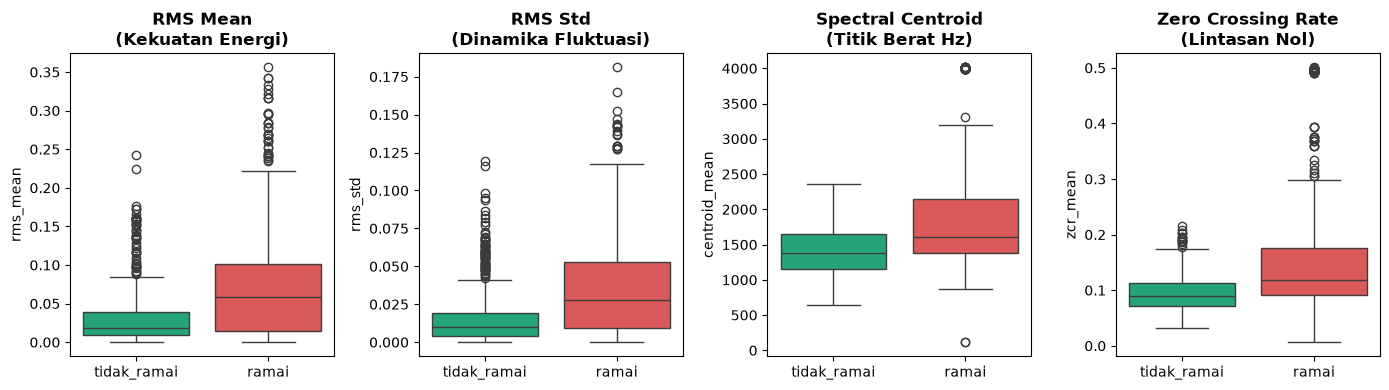

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(14, 4))
palette = {"ramai": "#ef4444", "tidak_ramai": "#10b981"}

sns.boxplot(data=df, x="class_name", y="rms_mean", palette=palette, hue="class_name", legend=False, ax=axs[0])
axs[0].set_title("RMS Mean\n(Kekuatan Energi)", fontweight="bold")
axs[0].set_xlabel("")

sns.boxplot(data=df, x="class_name", y="rms_std", palette=palette, hue="class_name", legend=False, ax=axs[1])
axs[1].set_title("RMS Std\n(Dinamika Fluktuasi)", fontweight="bold")
axs[1].set_xlabel("")

sns.boxplot(data=df, x="class_name", y="centroid_mean", palette=palette, hue="class_name", legend=False, ax=axs[2])
axs[2].set_title("Spectral Centroid\n(Titik Berat Hz)", fontweight="bold")
axs[2].set_xlabel("")

sns.boxplot(data=df, x="class_name", y="zcr_mean", palette=palette, hue="class_name", legend=False, ax=axs[3])
axs[3].set_title("Zero Crossing Rate\n(Lintasan Nol)", fontweight="bold")
axs[3].set_xlabel("")

plt.tight_layout()
plt.show()


---
## 2. Heatmap Korelasi Pearson Antar Fitur Utama terhadap Target
Korelasi linear menunjukkan kekuatan hubungan langsung masing-masing fitur dengan status keramaian ruangan (`label`).


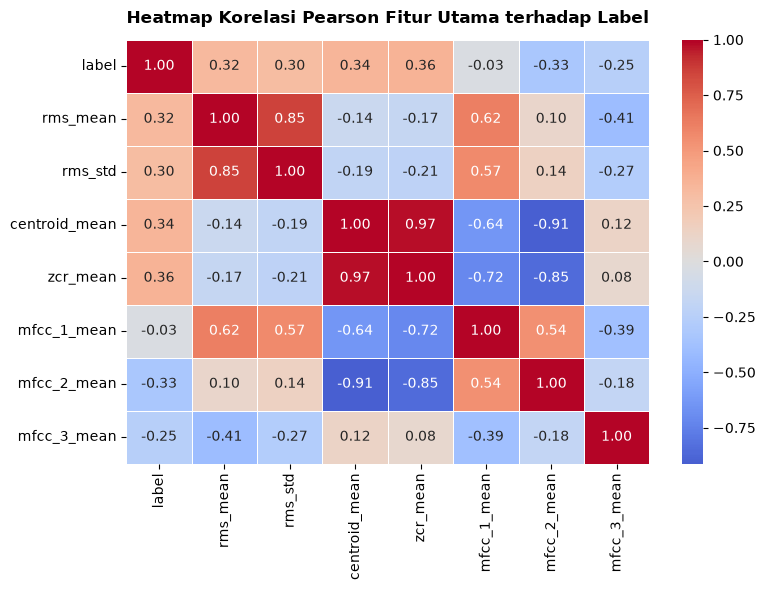

In [4]:
key_cols = ["label", "rms_mean", "rms_std", "centroid_mean", "zcr_mean", "mfcc_1_mean", "mfcc_2_mean", "mfcc_3_mean"]
corr_matrix = df[key_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, linewidths=0.5)
ax.set_title("Heatmap Korelasi Pearson Fitur Utama terhadap Label", fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


> **🧭 Navigasi Proyek CRISP-DM:**
> [🏠 00. Business Understanding](./00_Index_dan_Business_Understanding.ipynb) | [📊 01. Data Understanding & EDA](./01_Data_Understanding_dan_EDA.ipynb) | [⚙️ 02. Data Preparation & 32 Fitur](./02_Data_Preparation_Chunking_dan_Ekstraksi_32Fitur.ipynb) | [🧠 03. Modeling & Benchmarking](./03_Modeling_dan_Benchmarking.ipynb) | [🚀 04. Evaluation & Deployment](./04_Evaluation_dan_Simulasi_Deployment.ipynb)